In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from scipy import stats

In [2]:
TRK_FILE = (r"tracking_table_120min.parquet")

con = duckdb.connect("tracking_analysis.duckdb")

con.execute(
    f"""
    CREATE OR REPLACE VIEW TRACK_TABLE AS
    SELECT *
    FROM read_parquet('{TRK_FILE}', union_by_name = true)
    """
)

monthly_size = con.execute("""
    SELECT
        MAKE_DATE(YEAR(timestamp), MONTH(timestamp), 1) AS timestamp,
        region,
        SQRT(AVG(size) * 100 / PI()) AS mean_size
    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
      -- AND timestamp IS NOT NULL
      AND timestamp >= TIMESTAMP '2001-01-01'
      AND size IS NOT NULL
    GROUP BY
        YEAR(timestamp), MONTH(timestamp), region
    ORDER BY timestamp
""").fetchdf()

In [3]:
monthly_size["timestamp"] = pd.to_datetime(monthly_size["timestamp"])
monthly_size = monthly_size.pivot(index='timestamp', columns='region', values='mean_size').fillna(0)
monthly_size

region,NaN,north,south
timestamp,,,
2001-01-01,93.582738,80.535228,91.847573
2001-02-01,86.305470,80.459570,81.079065
2001-03-01,78.590119,78.278239,86.259097
2001-04-01,84.200412,59.303543,83.642074
2001-05-01,103.432177,58.474327,79.044013
...,...,...,...
2024-08-01,101.990952,37.401575,57.932209
2024-09-01,95.449621,49.036914,61.278209
2024-10-01,109.885893,71.833442,66.861435


In [4]:
df = monthly_size.copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

regions = ["north", "south"]

# STL DECOMPOSITION AND LINEAR TREND FOR EACH REGION

results_by_region = {}

for region in regions:
    series = df[region].astype(float).dropna().sort_index()
    full_index = pd.date_range(series.index.min(), series.index.max(), freq="MS")
    series = series.reindex(full_index)
    series.index.name = "timestamp"

    # STL decomposition
    stl_period=12
    result = STL(series, period=stl_period, robust=True).fit()

    observed = result.observed
    seasonal = result.seasonal
    trend = result.trend
    residual = result.resid
    deseasonalized = observed - seasonal

    # Linear regression
    x_years = ((deseasonalized.index - deseasonalized.index[0]).days / 365.25)
    X = sm.add_constant(x_years)
    model = sm.OLS(deseasonalized.to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    linear_fit = model.predict(X)
    slope_per_year = model.params[1]
    p_value = model.pvalues[1]
    r_squared = model.rsquared

    # Store everything needed for plotting
    results_by_region[region] = {
        "observed": observed,
        "seasonal": seasonal,
        "trend": trend,
        "residual": residual,
        "deseasonalized": deseasonalized,
        "linear_fit": linear_fit,
        "slope_per_year": slope_per_year,
        "p_value": p_value,
        "r_squared": r_squared
    }

    print(f"\nRegion: {region}")
    print(f"Slope:       {slope_per_year:.4f} km/year")
    print(f"Slope:       {slope_per_year * 10:.4f} km/decade")
    print(f"HAC p-value: {p_value:.4g}")
    print(f"R²:          {r_squared:.3f}")



Region: north
Slope:       0.0568 km/year
Slope:       0.5684 km/decade
HAC p-value: 0.4222
R²:          0.003

Region: south
Slope:       0.2244 km/year
Slope:       2.2438 km/decade
HAC p-value: 0.0009609
R²:          0.064


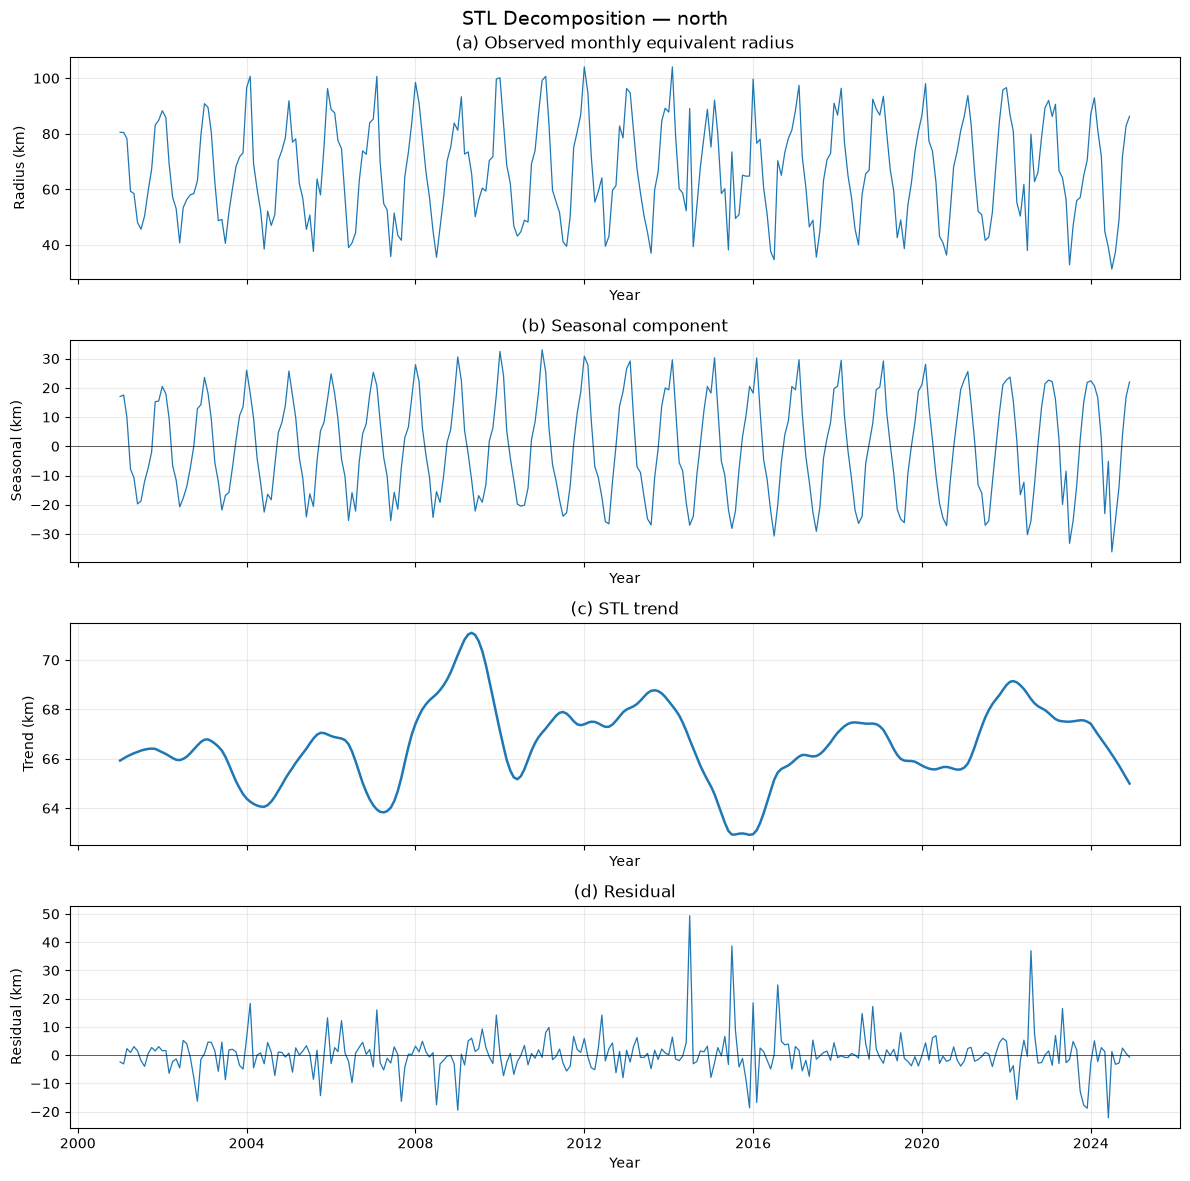

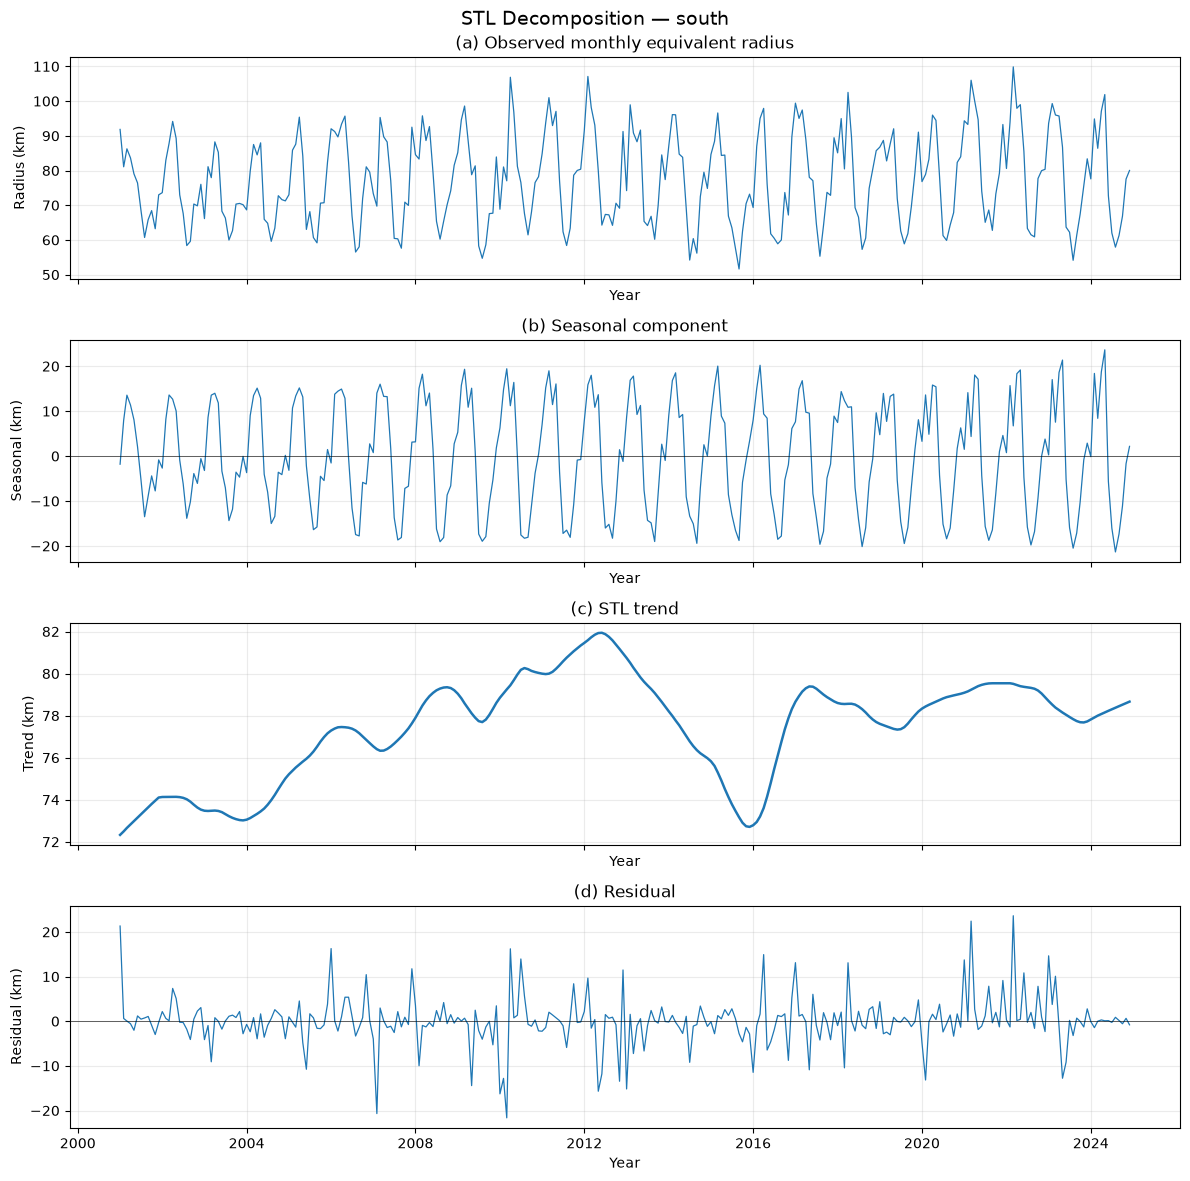

In [5]:
for region, r in results_by_region.items():

    fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

    axes[0].plot(r["observed"].index, r["observed"].to_numpy(), linewidth=0.9)
    axes[0].set_title("(a) Observed monthly equivalent radius")
    axes[0].set_ylabel("Radius (km)")

    axes[1].plot(r["seasonal"].index, r["seasonal"].to_numpy(), linewidth=0.9)
    axes[1].axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axes[1].set_title("(b) Seasonal component")
    axes[1].set_ylabel("Seasonal (km)")

    axes[2].plot(r["trend"].index, r["trend"].to_numpy(), linewidth=1.8)
    axes[2].set_title("(c) STL trend")
    axes[2].set_ylabel("Trend (km)")

    axes[3].plot(r["residual"].index, r["residual"].to_numpy(), linewidth=0.9)
    axes[3].axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axes[3].set_title("(d) Residual")
    axes[3].set_ylabel("Residual (km)")

    for ax in axes:
        ax.set_xlabel("Year")
        ax.grid(alpha=0.25)

    fig.suptitle(f"STL Decomposition — {region}", fontsize=14)
    plt.tight_layout()
    plt.show()

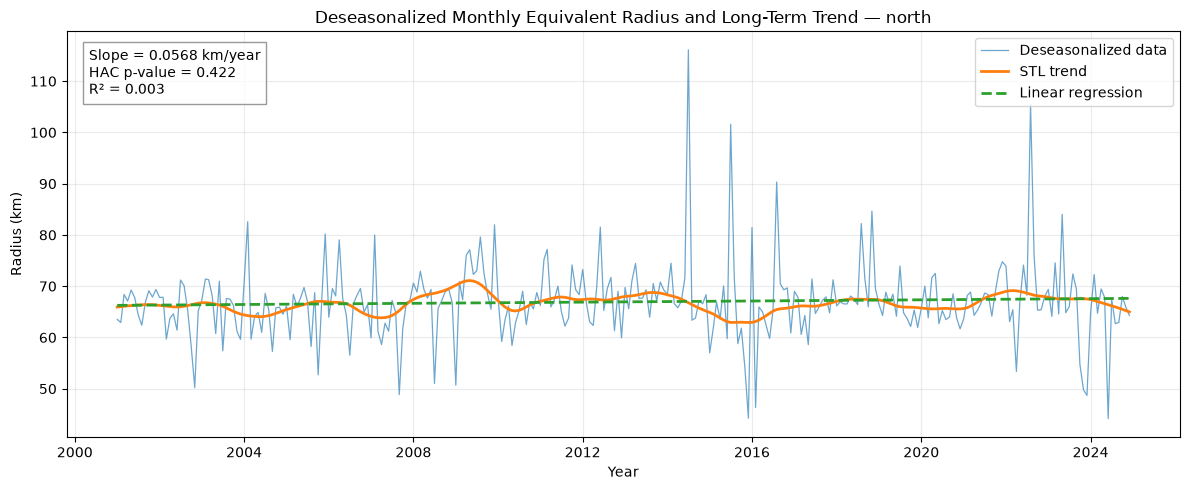

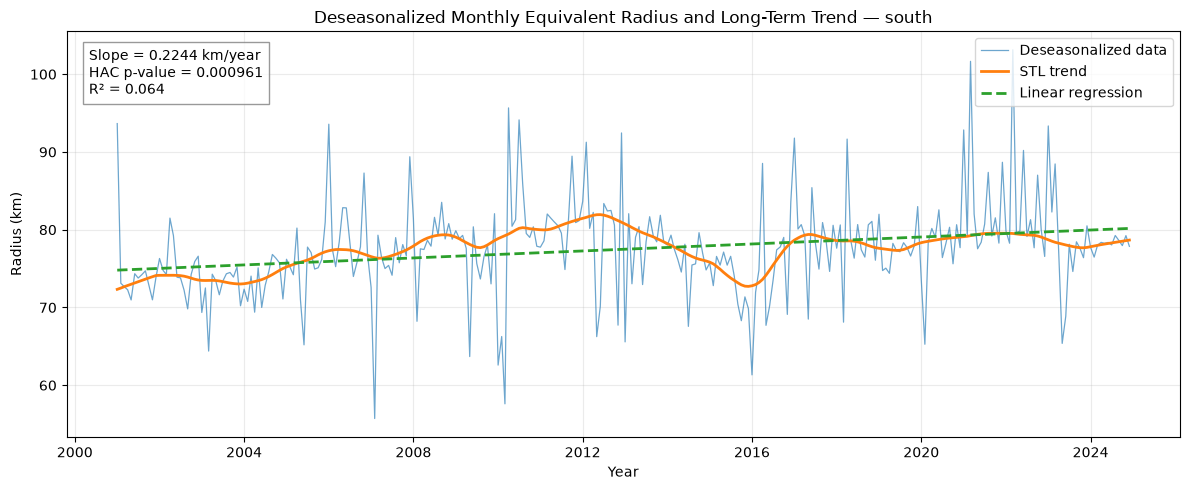

In [6]:
for region, r in results_by_region.items():
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(r["deseasonalized"].index, r["deseasonalized"].to_numpy(), linewidth=0.9, alpha=0.65, label="Deseasonalized data")
    ax.plot(r["trend"].index, r["trend"].to_numpy(), linewidth=2, label="STL trend")
    ax.plot(r["deseasonalized"].index, r["linear_fit"], linestyle="--", linewidth=2, label="Linear regression")

    ax.set_title(f"Deseasonalized Monthly Equivalent Radius and Long-Term Trend — {region}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Radius (km)")
    ax.grid(alpha=0.25)

    ax.text(0.02, 0.96, f"Slope = {r['slope_per_year']:.4f} km/year\n" f"HAC p-value = {r['p_value']:.3g}\n" f"R² = {r['r_squared']:.3f}",
        transform=ax.transAxes, verticalalignment="top", bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))

    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

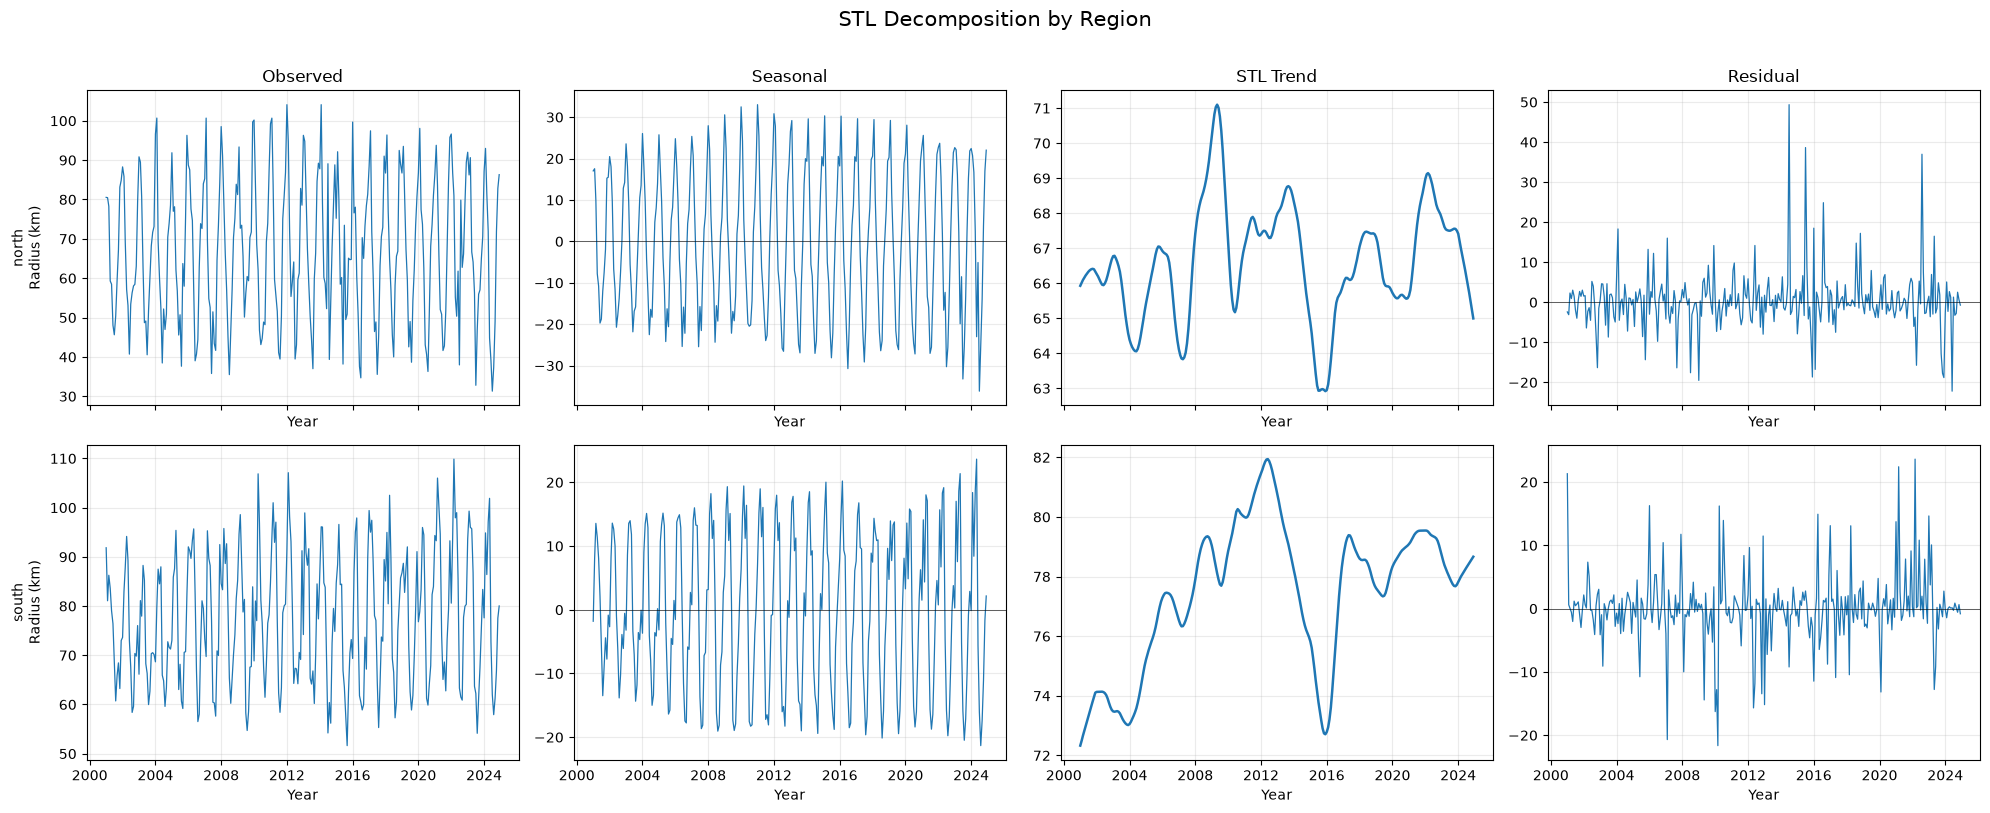

In [7]:
# Plot STL decomposition for all regions in one figure

regions_to_plot = list(results_by_region.keys())

fig, axes = plt.subplots(len(regions_to_plot), 4, figsize=(20, 4 * len(regions_to_plot)), sharex=True, squeeze=False)

for i, region in enumerate(regions_to_plot):
    r = results_by_region[region]
    # Observed data
    axes[i, 0].plot(r["observed"].index, r["observed"].to_numpy(), linewidth=0.9)
    axes[i, 0].set_ylabel(f"{region}\nRadius (km)")
    axes[i, 0].set_title("Observed" if i == 0 else "")
    # Seasonal component
    axes[i, 1].plot(r["seasonal"].index, r["seasonal"].to_numpy(), linewidth=0.9)
    axes[i, 1].axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axes[i, 1].set_title("Seasonal" if i == 0 else "")
    # STL trend
    axes[i, 2].plot(r["trend"].index, r["trend"].to_numpy(), linewidth=1.8)
    axes[i, 2].set_title("STL Trend" if i == 0 else "")

    # Residual
    axes[i, 3].plot(r["residual"].index, r["residual"].to_numpy(), linewidth=0.9)
    axes[i, 3].axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axes[i, 3].set_title("Residual" if i == 0 else "")

    for j in range(4):
        axes[i, j].grid(alpha=0.25)
        axes[i, j].set_xlabel("Year")

fig.suptitle("STL Decomposition by Region", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

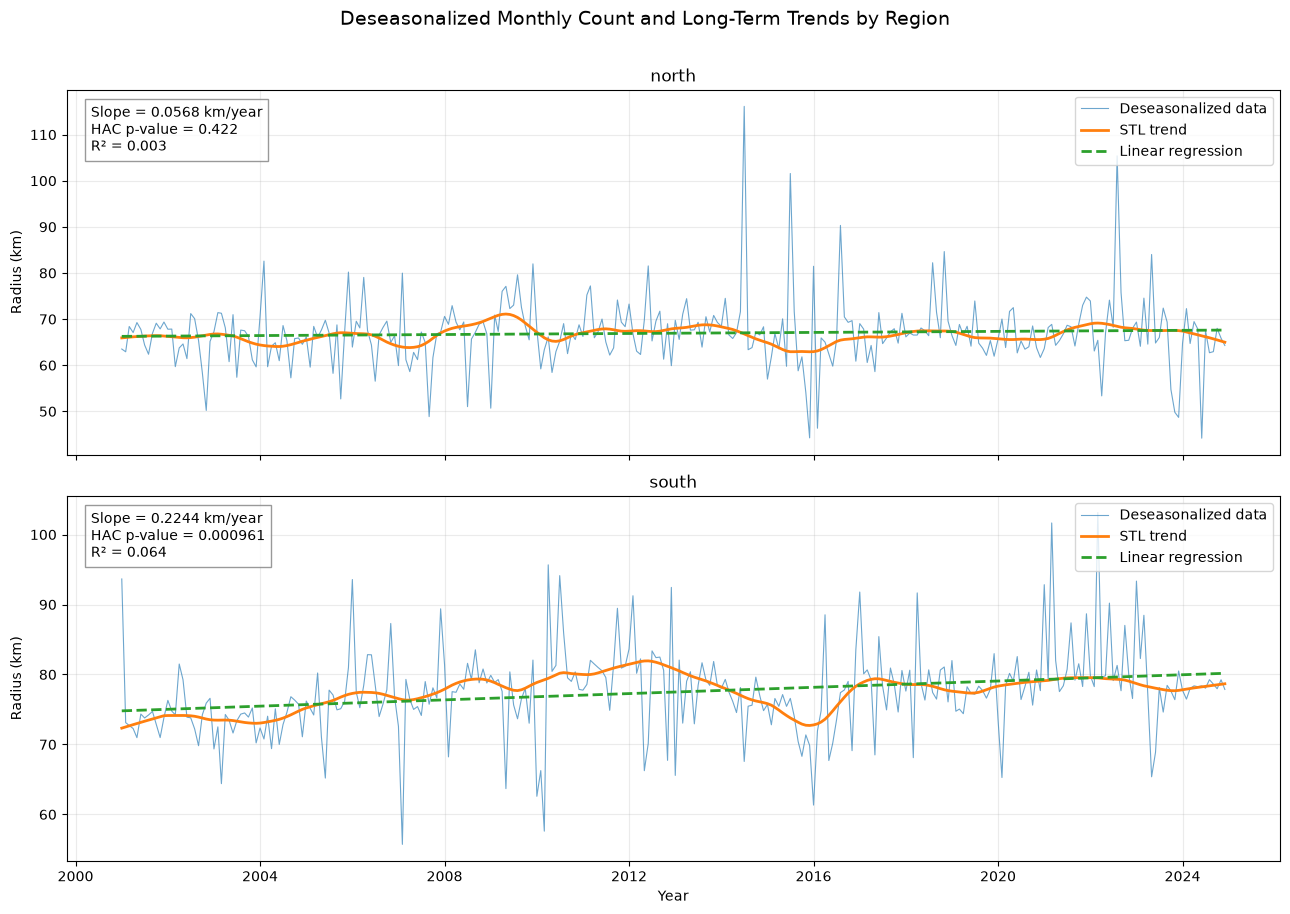

In [8]:
# Plot deseasonalized data and trends for all regions

fig, axes = plt.subplots(len(regions_to_plot), 1, figsize=(13, 4.5 * len(regions_to_plot)),sharex=True,squeeze=False)

for i, region in enumerate(regions_to_plot):
    ax = axes[i, 0]
    r = results_by_region[region]
    ax.plot(r["deseasonalized"].index,r["deseasonalized"].to_numpy(),linewidth=0.8,alpha=0.65,label="Deseasonalized data")
    ax.plot(r["trend"].index,r["trend"].to_numpy(),linewidth=2,label="STL trend")
    ax.plot(r["deseasonalized"].index,r["linear_fit"],linestyle="--",linewidth=2,label="Linear regression")

    ax.set_title(region)
    ax.set_ylabel("Radius (km)")
    ax.grid(alpha=0.25)

    ax.text(0.02, 0.96,f"Slope = {r['slope_per_year']:.4f} km/year\n" f"HAC p-value = {r['p_value']:.3g}\n" f"R² = {r['r_squared']:.3f}",
        transform=ax.transAxes,verticalalignment="top",bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))
    ax.legend(loc="upper right")

axes[-1, 0].set_xlabel("Year")

fig.suptitle("Deseasonalized Monthly Count and Long-Term Trends by Region",fontsize=14,y=1.01)

plt.tight_layout()
plt.show()

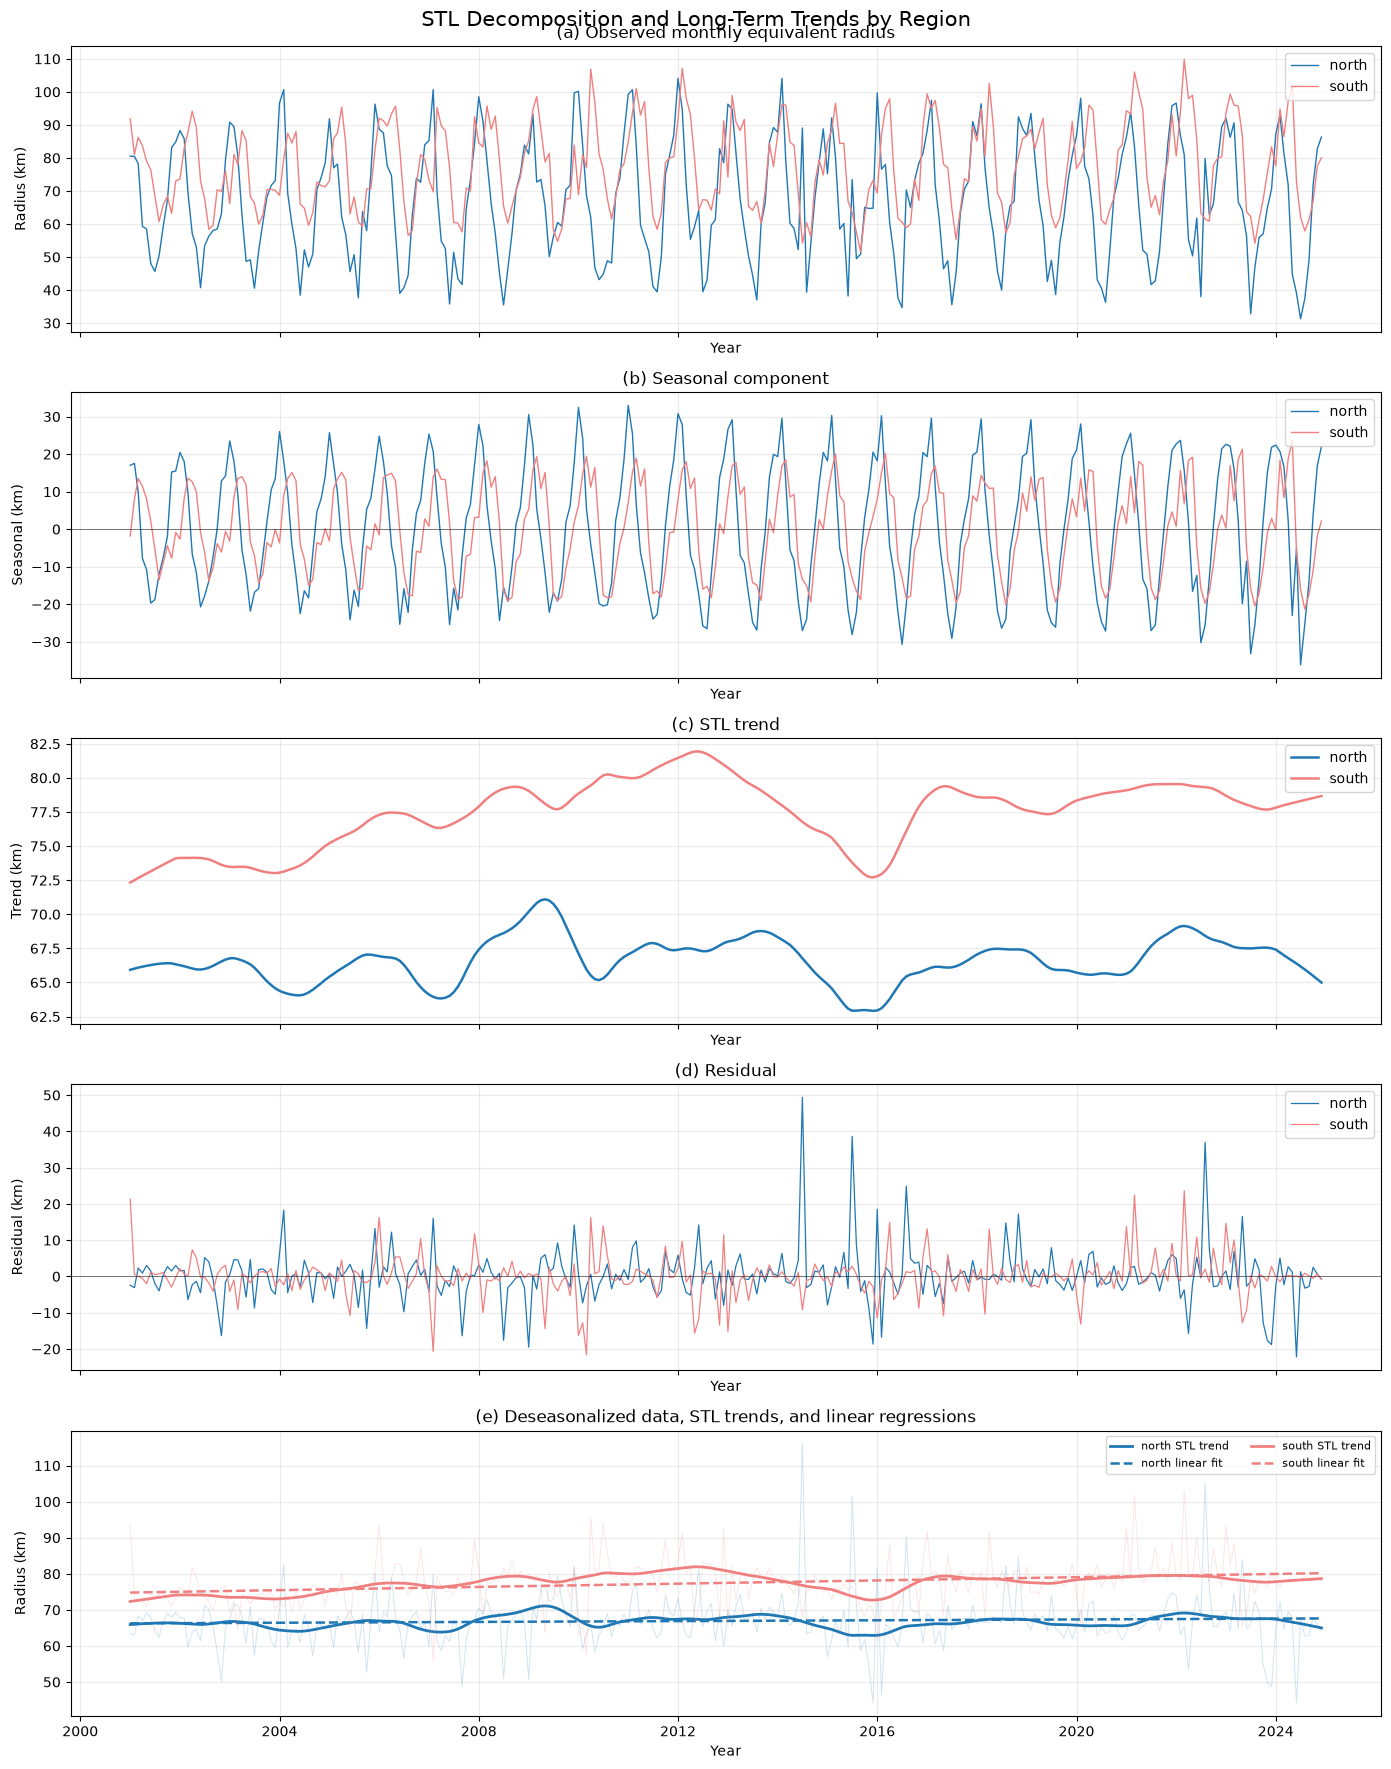

In [9]:
# STL decomposition for all regions

regions_to_plot = ["north", "south"]

colors = {
    "nan": "gray",
    "north": "tab:blue",
    "south": "lightcoral"
}

fig, axes = plt.subplots(5, 1, figsize=(14, 18),sharex=True)

for region in regions_to_plot:
    if region not in results_by_region:
        continue

    r = results_by_region[region]
    color = colors[region]

    axes[0].plot(r["observed"].index, r["observed"].to_numpy(),color=color, linewidth=1, label=region)
    axes[1].plot(r["seasonal"].index, r["seasonal"].to_numpy(),color=color, linewidth=1, label=region)
    axes[2].plot(r["trend"].index, r["trend"].to_numpy(),color=color, linewidth=1.8, label=region)
    axes[3].plot(r["residual"].index, r["residual"].to_numpy(),color=color, linewidth=0.9, label=region)

axes[0].set_title("(a) Observed monthly equivalent radius")
axes[0].set_ylabel("Radius (km)")

axes[1].set_title("(b) Seasonal component")
axes[1].set_ylabel("Seasonal (km)")
axes[1].axhline(0, color="black", linewidth=0.7, alpha=0.5)

axes[2].set_title("(c) STL trend")
axes[2].set_ylabel("Trend (km)")

axes[3].set_title("(d) Residual")
axes[3].set_ylabel("Residual (km)")
axes[3].axhline(0, color="black", linewidth=0.7, alpha=0.5)

# Deseasonalized data, STL trend, and linear fit

for region in regions_to_plot:

    if region not in results_by_region:
        continue

    r = results_by_region[region]
    color = colors[region]

    # Deseasonalized observations
    axes[4].plot(r["deseasonalized"].index, r["deseasonalized"].to_numpy(), color=color, linewidth=0.7, alpha=0.2)

    # STL trend
    axes[4].plot(r["trend"].index,r["trend"].to_numpy(),color=color,linewidth=2,label=f"{region} STL trend")

    # Linear regression
    axes[4].plot(r["deseasonalized"].index,r["linear_fit"],color=color,linestyle="--",linewidth=1.8,label=f"{region} linear fit")

axes[4].set_title("(e) Deseasonalized data, STL trends, and linear regressions")
axes[4].set_ylabel("Radius (km)")

for ax in axes:
    ax.set_xlabel("Year")
    ax.grid(alpha=0.25)

# Legends for the first four panels
for ax in axes[:4]:
    ax.legend(loc="upper right")

# Legend for the final panel
axes[4].legend(loc="upper right", ncol=2, fontsize=8)

fig.suptitle("STL Decomposition and Long-Term Trends by Region", fontsize=15)

plt.tight_layout()
plt.show()

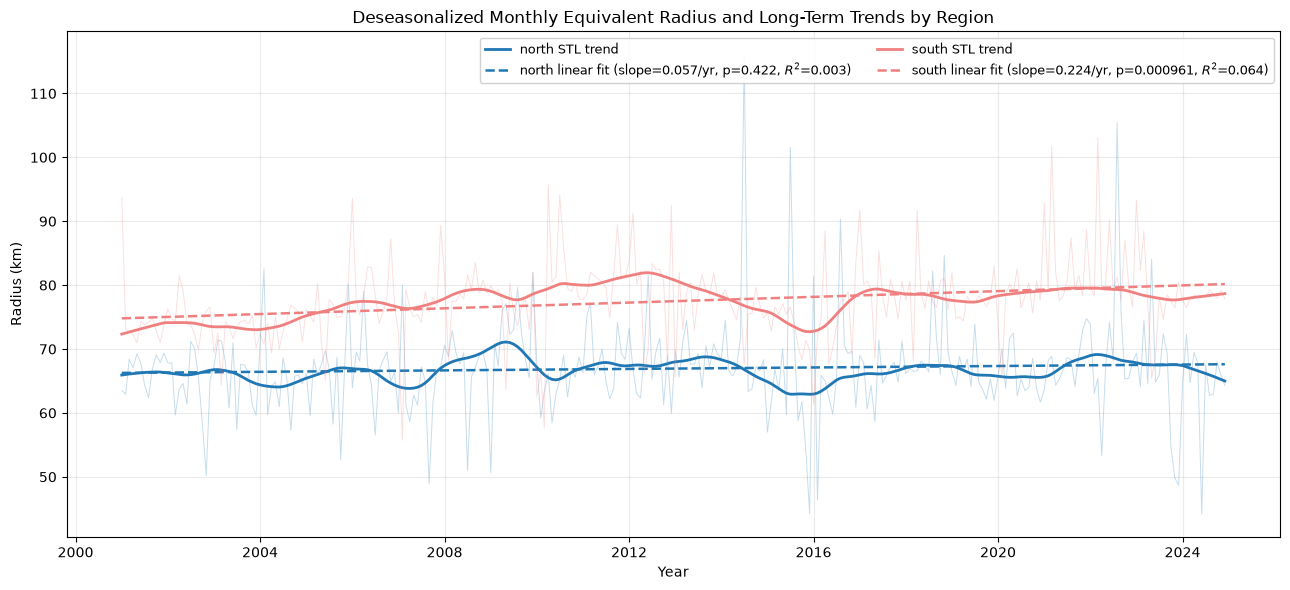

In [10]:
fig, ax = plt.subplots(figsize=(13, 6))

for region in regions_to_plot:

    if region not in results_by_region:
        continue

    r = results_by_region[region]
    color = colors[region]

    # Deseasonalized observations (faint)
    ax.plot(r["deseasonalized"].index, r["deseasonalized"].to_numpy(), color=color, linewidth=0.7, alpha=0.25)

    # STL trend
    ax.plot(r["trend"].index,r["trend"].to_numpy(),color=color,linewidth=2,label=f"{region} STL trend")

    # Linear regression with parameters in the legend
    slope = r["slope_per_year"]
    p_value = r["p_value"]
    r_squared = r["r_squared"]

    fit_label = (
        f"{region} linear fit "
        f"(slope={slope:.3f}/yr, "
        f"p={p_value:.3g}, "
        f"$R^2$={r_squared:.3f})")

    ax.plot(r["deseasonalized"].index, r["linear_fit"], color=color, linestyle="--", linewidth=1.8, label=fit_label)

ax.set_title("Deseasonalized Monthly Equivalent Radius and Long-Term Trends by Region")
ax.set_xlabel("Year")
ax.set_ylabel("Radius (km)")
ax.grid(alpha=0.25)

ax.legend(loc="best", ncol=2, fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.show()

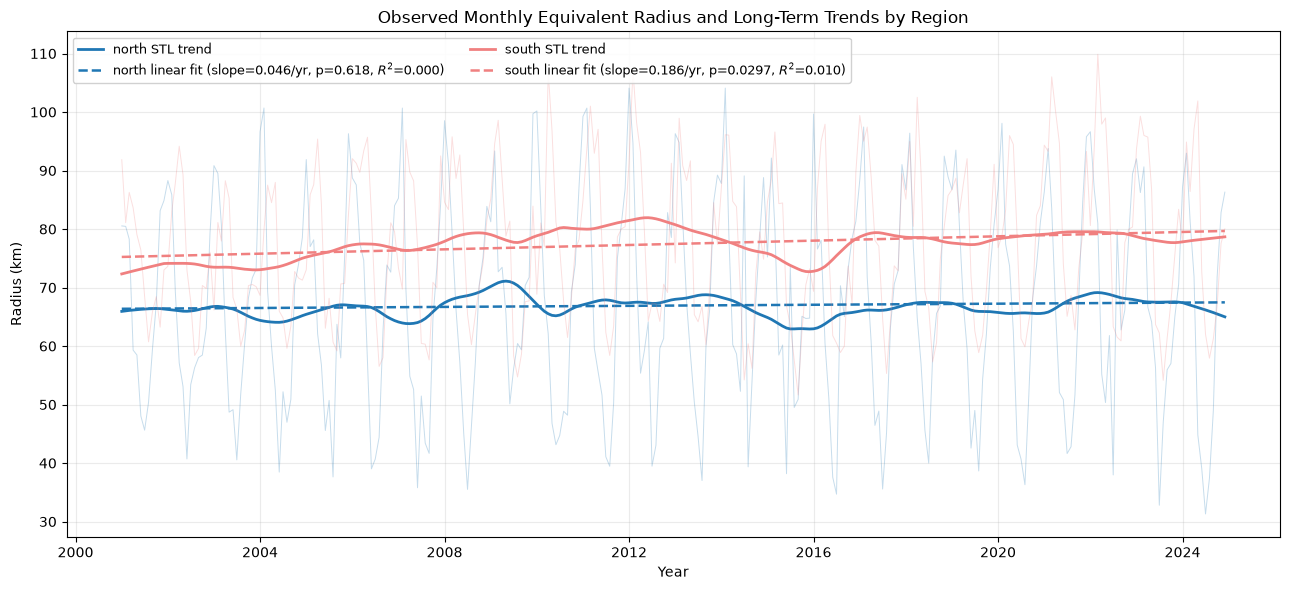

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))

for region in regions_to_plot:

    if region not in results_by_region:
        continue

    r = results_by_region[region]
    color = colors[region]

    # Observed raw monthly counts
    observed = r["observed"].dropna()

    # Convert dates to elapsed years
    x_years = ((observed.index - observed.index[0]).days / 365.25)

    # Linear regression with HAC standard errors
    X = sm.add_constant(x_years)
    model = sm.OLS(observed.to_numpy(),X).fit(cov_type="HAC",cov_kwds={"maxlags": 12})
    linear_fit = model.predict(X)
    slope_per_year = model.params[1]
    p_value = model.pvalues[1]
    r_squared = model.rsquared

    # Observed raw data
    ax.plot(observed.index,observed.to_numpy(),color=color,linewidth=0.7,alpha=0.25)

    # STL trend (from the original decomposition)
    ax.plot(r["trend"].index,r["trend"].to_numpy(),color=color,linewidth=2,label=f"{region} STL trend")

    # Linear regression with parameters in the legend
    fit_label = (
        f"{region} linear fit "
        f"(slope={slope_per_year:.3f}/yr, "
        f"p={p_value:.3g}, "
        f"$R^2$={r_squared:.3f})")

    ax.plot(observed.index,linear_fit,color=color,linestyle="--",linewidth=1.8,label=fit_label)

ax.set_title("Observed Monthly Equivalent Radius and Long-Term Trends by Region")
ax.set_xlabel("Year")
ax.set_ylabel("Radius (km)")
ax.grid(alpha=0.25)

ax.legend(
    loc="best",
    ncol=2,
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()